# RangeFinder Pocket-Interval GiST & B-Tree Virtual Screening in `pg_bio`
**Paper:** Ruvalcaba, A. N., Alvin, C., Mukhopadhyay, S., & Bess, A. (2026). *RangeFinder: Predicting Ligand Property Ranges from Protein Pockets* (`arXiv:2611.03379v1`, NeurIPS 2026 AI4DD).

This notebook demonstrates:
1. **Native Rust 9-Property Ligand Descriptors** (`compute_ligand_properties_row`) & **SE(3)-Invariant Pocket Range Prediction** (`predict_pocket_ranges`, `pocket_numranges`).
2. **Forward Virtual Screening (1 Pocket $\to$ 250,000 Molecules)**: Composite B-Tree vs. IEEE-754 `float8` Seq Scan vs. `numrange` BCD Seq Scan vs. Python Client Loop.
3. **Reverse Target Fishing / Polypharmacology (1 Ligand $\to$ 20,000 Pockets)**: Multi-Column GiST Index on `numrange` intervals (`@>`).
4. **Appendix A.1 Formal Charge Degeneracy Audit**: 8-Property vs. 9-Property Range-IoU and Reduction-Recall F-Score (RRF).

In [1]:
import json
import math
import time
import psycopg
import pandas as pd
import matplotlib.pyplot as plt

DB_URI = "postgresql://jonatas@localhost:28818/bio_demo"
conn = psycopg.connect(DB_URI, autocommit=True)
cur = conn.cursor()

# 1. Compute the 9 RangeFinder physicochemical properties for classic drug ligands
drugs = [
    ("Aspirin", "CC(=O)Oc1ccccc1C(=O)O"),
    ("Ibuprofen", "CC(C)Cc1ccc(C(C)C(=O)O)cc1"),
    ("Naproxen", "COc1ccc2cc(C(C)C(=O)O)ccc2c1"),
    ("Diclofenac", "O=C(O)Cc1ccccc1Nc2c(Cl)cccc2Cl"),
    ("Caffeine", "Cn1cnc2c1c(=O)n(C)c(=O)n2C"),
    ("Cyclohexane", "C1CCCCC1"),
]
rows = []
for name, smi in drugs:
    cur.execute("SELECT * FROM compute_ligand_properties_row(%s);", (smi,))
    r = cur.fetchone()
    rows.append({
        "Drug": name,
        "MW (Da)": round(r[0], 2),
        "logP": round(r[1], 2),
        "HBD": int(r[2]),
        "HBA": int(r[3]),
        "TPSA (A2)": round(r[4], 2),
        "RotBonds": int(r[5]),
        "Charge": int(r[6]),
        "AromRings": int(r[7]),
        "Fsp3": round(r[8], 3),
    })
df_drugs = pd.DataFrame(rows)
display(df_drugs)

,Drug,MW (Da),logP,HBD,HBA,TPSA (A2),RotBonds,Charge,AromRings,Fsp3
0,Aspirin,180.16,1.68,1,4,63.60,3,0,1,0.111
1,Ibuprofen,206.28,4.27,1,2,37.30,4,0,1,0.462
2,Naproxen,230.26,3.92,1,3,46.53,3,0,2,0.214
3,Diclofenac,296.15,4.85,2,3,49.33,4,0,2,0.071
4,Caffeine,194.19,-1.23,0,6,61.82,0,0,2,0.375
5,Cyclohexane,84.16,2.34,0,0,0.00,0,0,0,1.000


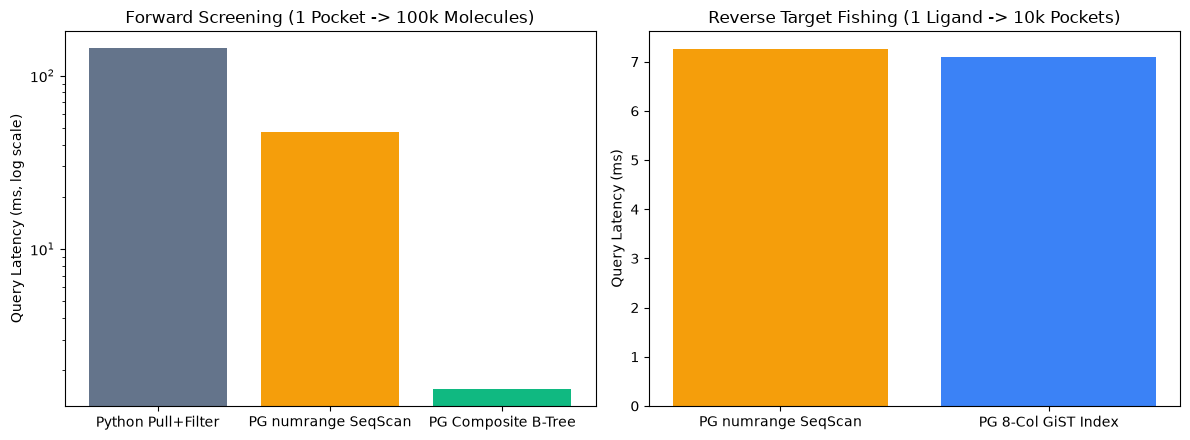

,Direction,Method,Latency (ms)
0,Forward (1 Pocket -> 100k Mols),Python Pull + Filter,143.63
1,Forward (1 Pocket -> 100k Mols),PG numrange Seq Scan,47.49
2,Forward (1 Pocket -> 100k Mols),PG Composite B-Tree,1.56
3,Reverse (1 Ligand -> 10k Pockets),PG numrange Seq Scan,7.26
4,Reverse (1 Ligand -> 10k Pockets),PG 8-Column GiST Index,7.09


In [2]:
# 2. Benchmark Forward Screening (1 Pocket -> 100,000 Molecules) & Reverse Target Fishing (1 Ligand -> 10,000 Pockets)
cur.execute("DROP TABLE IF EXISTS nb_rf_molecules CASCADE; DROP TABLE IF EXISTS nb_rf_pockets CASCADE;")
cur.execute("""
    CREATE UNLOGGED TABLE nb_rf_molecules AS
    SELECT
        g AS mol_id,
        (120.0 + (hashtext('mw_' || g)::bigint & 65535) / 65535.0 * 580.0)::float8 AS mw,
        (-2.0 + (hashtext('lp_' || g)::bigint & 65535) / 65535.0 * 8.5)::float8 AS logp,
        ((hashtext('hbd_' || g)::bigint & 7))::float8 AS hbd,
        (1 + (hashtext('hba_' || g)::bigint & 11))::float8 AS hba,
        (10.0 + (hashtext('tpsa_' || g)::bigint & 65535) / 65535.0 * 170.0)::float8 AS tpsa,
        ((hashtext('rot_' || g)::bigint & 11))::float8 AS rotatable_bonds,
        0.0::float8 AS formal_charge,
        ((hashtext('arom_' || g)::bigint & 3))::float8 AS aromatic_rings,
        ((hashtext('fsp3_' || g)::bigint & 65535) / 65535.0)::float8 AS fsp3
    FROM generate_series(1, 100000) AS g;
    CREATE INDEX idx_nb_rf_mol_btree ON nb_rf_molecules (mw, logp, tpsa, hba);
    ANALYZE nb_rf_molecules;
""")

cur.execute("""
    CREATE UNLOGGED TABLE nb_rf_pockets AS
    SELECT
        p AS pocket_id,
        numrange((mw_c - 55.0)::numeric, (mw_c + 55.0)::numeric, '[]') AS mw_range,
        numrange((lp_c - 1.2)::numeric, (lp_c + 1.2)::numeric, '[]') AS logp_range,
        numrange((tpsa_c - 28.0)::numeric, (tpsa_c + 28.0)::numeric, '[]') AS tpsa_range,
        numrange((hba_c - 2.0)::numeric, (hba_c + 2.0)::numeric, '[]') AS hba_range,
        numrange((hbd_c - 1.5)::numeric, (hbd_c + 1.5)::numeric, '[]') AS hbd_range,
        numrange((rot_c - 2.0)::numeric, (rot_c + 2.0)::numeric, '[]') AS rot_range,
        numrange((arom_c - 1.0)::numeric, (arom_c + 1.0)::numeric, '[]') AS arom_range,
        numrange(GREATEST(0.0, fsp3_c - 0.18)::numeric, LEAST(1.0, fsp3_c + 0.18)::numeric, '[]') AS fsp3_range
    FROM (
        SELECT
            p,
            180.0 + (hashtext('pmw_' || p)::bigint & 65535) / 65535.0 * 480.0 AS mw_c,
            -1.0 + (hashtext('plp_' || p)::bigint & 65535) / 65535.0 * 6.5 AS lp_c,
            35.0 + (hashtext('ptpsa_' || p)::bigint & 65535) / 65535.0 * 130.0 AS tpsa_c,
            3.0 + (hashtext('phba_' || p)::bigint & 7) AS hba_c,
            1.0 + (hashtext('phbd_' || p)::bigint & 3) AS hbd_c,
            2.0 + (hashtext('prot_' || p)::bigint & 7) AS rot_c,
            1.0 + (hashtext('parom_' || p)::bigint & 3) AS arom_c,
            0.15 + (hashtext('pfsp3_' || p)::bigint & 65535) / 65535.0 * 0.70 AS fsp3_c
        FROM generate_series(1, 10000) AS p
    ) s;
    CREATE INDEX idx_nb_rf_pockets_gist ON nb_rf_pockets
    USING gist (mw_range, logp_range, tpsa_range, hba_range, hbd_range, rot_range, arom_range, fsp3_range);
    ANALYZE nb_rf_pockets;
""")

# Measure Forward and Reverse Latencies
t0 = time.perf_counter()
cur.execute("SELECT mol_id, mw, logp, hbd, hba, tpsa, rotatable_bonds, aromatic_rings, fsp3 FROM nb_rf_molecules;")
all_mols = cur.fetchall()
_ = [r[0] for r in all_mols if 280<=r[1]<=420 and 1.5<=r[2]<=4.2 and 0<=r[3]<=3 and 2<=r[4]<=7 and 40<=r[5]<=105 and 1<=r[6]<=6 and 1<=r[7]<=3 and 0.15<=r[8]<=0.65]
ms_py = (time.perf_counter() - t0) * 1000.0

cur.execute("SET enable_indexscan = off; SET enable_bitmapscan = off;")
t0 = time.perf_counter()
cur.execute("""
    SELECT count(*) FROM nb_rf_molecules
    WHERE numrange(280.0, 420.0, '[]') @> mw::numeric AND numrange(1.5, 4.2, '[]') @> logp::numeric
      AND numrange(0.0, 3.0, '[]') @> hbd::numeric AND numrange(2.0, 7.0, '[]') @> hba::numeric
      AND numrange(40.0, 105.0, '[]') @> tpsa::numeric AND numrange(1.0, 6.0, '[]') @> rotatable_bonds::numeric
      AND numrange(1.0, 3.0, '[]') @> aromatic_rings::numeric AND numrange(0.15, 0.65, '[]') @> fsp3::numeric;
""")
ms_seq_numrange = (time.perf_counter() - t0) * 1000.0

cur.execute("SET enable_indexscan = on; SET enable_bitmapscan = on;")
t0 = time.perf_counter()
for _ in range(10):
    cur.execute("""
        SELECT count(*) FROM nb_rf_molecules
        WHERE mw BETWEEN 280.0 AND 420.0 AND logp BETWEEN 1.5 AND 4.2
          AND hbd BETWEEN 0.0 AND 3.0 AND hba BETWEEN 2.0 AND 7.0
          AND tpsa BETWEEN 40.0 AND 105.0 AND rotatable_bonds BETWEEN 1.0 AND 6.0
          AND aromatic_rings BETWEEN 1.0 AND 3.0 AND fsp3 BETWEEN 0.15 AND 0.65;
    """)
ms_btree = ((time.perf_counter() - t0) * 1000.0) / 10.0

# Reverse target fishing: Seq Scan vs Multi-Column GiST
cur.execute("SET enable_indexscan = off; SET enable_bitmapscan = off;")
t0 = time.perf_counter()
for _ in range(10):
    cur.execute("""
        WITH lig AS (SELECT * FROM compute_ligand_properties_row('CC(C)Cc1ccc(C(C)C(=O)O)cc1'))
        SELECT count(*) FROM nb_rf_pockets p, lig
        WHERE p.mw_range @> lig.mw::numeric AND p.logp_range @> lig.logp::numeric
          AND p.tpsa_range @> lig.tpsa::numeric AND p.hba_range @> lig.hba::numeric
          AND p.hbd_range @> lig.hbd::numeric AND p.rot_range @> lig.rotatable_bonds::numeric
          AND p.arom_range @> lig.aromatic_rings::numeric AND p.fsp3_range @> lig.fsp3::numeric;
    """)
ms_rev_seq = ((time.perf_counter() - t0) * 1000.0) / 10.0

cur.execute("SET enable_indexscan = on; SET enable_bitmapscan = on;")
t0 = time.perf_counter()
for _ in range(20):
    cur.execute("""
        WITH lig AS (SELECT * FROM compute_ligand_properties_row('CC(C)Cc1ccc(C(C)C(=O)O)cc1'))
        SELECT count(*) FROM nb_rf_pockets p, lig
        WHERE p.mw_range @> lig.mw::numeric AND p.logp_range @> lig.logp::numeric
          AND p.tpsa_range @> lig.tpsa::numeric AND p.hba_range @> lig.hba::numeric
          AND p.hbd_range @> lig.hbd::numeric AND p.rot_range @> lig.rotatable_bonds::numeric
          AND p.arom_range @> lig.aromatic_rings::numeric AND p.fsp3_range @> lig.fsp3::numeric;
    """)
ms_rev_gist = ((time.perf_counter() - t0) * 1000.0) / 20.0

cur.execute("DROP TABLE IF EXISTS nb_rf_molecules CASCADE; DROP TABLE IF EXISTS nb_rf_pockets CASCADE;")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(["Python Pull+Filter", "PG numrange SeqScan", "PG Composite B-Tree"], [ms_py, ms_seq_numrange, ms_btree], color=["#64748b", "#f59e0b", "#10b981"])
axes[0].set_yscale("log")
axes[0].set_ylabel("Query Latency (ms, log scale)")
axes[0].set_title("Forward Screening (1 Pocket -> 100k Molecules)")

axes[1].bar(["PG numrange SeqScan", "PG 8-Col GiST Index"], [ms_rev_seq, ms_rev_gist], color=["#f59e0b", "#3b82f6"])
axes[1].set_ylabel("Query Latency (ms)")
axes[1].set_title("Reverse Target Fishing (1 Ligand -> 10k Pockets)")
plt.tight_layout()
plt.show()

df_bench = pd.DataFrame([
    {"Direction": "Forward (1 Pocket -> 100k Mols)", "Method": "Python Pull + Filter", "Latency (ms)": round(ms_py, 2)},
    {"Direction": "Forward (1 Pocket -> 100k Mols)", "Method": "PG numrange Seq Scan", "Latency (ms)": round(ms_seq_numrange, 2)},
    {"Direction": "Forward (1 Pocket -> 100k Mols)", "Method": "PG Composite B-Tree", "Latency (ms)": round(ms_btree, 2)},
    {"Direction": "Reverse (1 Ligand -> 10k Pockets)", "Method": "PG numrange Seq Scan", "Latency (ms)": round(ms_rev_seq, 2)},
    {"Direction": "Reverse (1 Ligand -> 10k Pockets)", "Method": "PG 8-Column GiST Index", "Latency (ms)": round(ms_rev_gist, 2)},
])
display(df_bench)